# Predictions statistics

Let's analyse the predictions made on our test datasplit.

**Note** To run this notebook you previously have to run and save the predictions on a test dataset **with ground-truth labels**. See the Datasplit section in [3.0 notebook](./3.0-Computing_predictions.ipynb#Predicting-a-datasplit-txt-file) for reference.


import packages

In [19]:
import os
import json
import warnings
from pathlib import Path

from planktonclass import test_utils, config, paths, plot_utils
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score
from planktonclass.data_utils import load_image, load_class_names
from planktonclass.plot_utils import create_pred_path, plt_conf_matrix
import numpy as np
import pandas as pd
import datetime
import matplotlib.pyplot as plt
import seaborn
from tqdm import tqdm

warnings.filterwarnings('ignore')
warnings.filterwarnings(
    'ignore',
    category=FutureWarning,
    message=r'.*`np\.object` will be defined as the corresponding NumPy scalar.*',
)

def find_project_config(start=None):
    start = Path.cwd().resolve() if start is None else Path(start).resolve()
    candidates = [start, start.parent]
    for root in candidates:
        conf_path = root / 'config.yaml'
        if conf_path.exists():
            return conf_path
    for root in [start, *start.parents]:
        conf_path = root / 'config.yaml'
        if conf_path.exists():
            return conf_path
    raise FileNotFoundError('Could not find config.yaml in the current project. Start Jupyter in the project root or its notebooks folder.')

CONF_PATH = find_project_config()
PROJECT_DIR = CONF_PATH.parent
config.set_config_path(str(CONF_PATH))
paths.CONF = config.get_conf_dict()
print(f"Using project config: {os.path.relpath(CONF_PATH, Path.cwd())}")


Using project config: ..\config.yaml


In [20]:

# User parameters to set
TIMESTAMP = '2026-09-04_115513-eriozona'           # CHANGE THIS for your own run; pretrained default
SPLIT_NAME = 'DS_split'                   # dataset split to predict
MODEL_NAME = 'best_model.keras'         # CHANGE THIS checkpoint; pretrained default, local runs often use best_model.keras or final_model.keras
TOP_K = 5                             # number of top classes predictions to save

# Set the timestamp
paths.timestamp = TIMESTAMP

# Load clas names
class_names = load_class_names(splits_dir=paths.get_ts_splits_dir())

# Load back the predictions
pred_path = os.path.join(paths.get_predictions_dir(), '{}+{}+top{}.json'.format(MODEL_NAME, SPLIT_NAME, TOP_K))
with open(pred_path) as f:
    pred_dict = json.load(f)

def resolve_saved_filename(path):
    if os.path.isabs(path):
        return path
    return os.path.abspath(os.path.join(paths.get_base_dir(), path))

pred_dict['filenames_absolute'] = [resolve_saved_filename(path) for path in pred_dict['filenames']]
data = pd.DataFrame(pred_dict)
data[['filenames', 'true_lab','pred_lab']].head(5)
data['in_top5'] = data.apply(lambda row: row['true_lab'] in row['pred_lab'], axis=1)
data['top1_correct'] = data.apply(lambda row: row['true_lab'] == row['pred_lab'][0], axis=1)
data['true_label']=class_names[data['true_lab']]
data['top1']=data.apply(lambda row: class_names[row['pred_lab'][0]], axis=1)
data['probability']=data.apply(lambda row: row['pred_prob'][0], axis=1)
flat_array=np.concatenate(np.array(pred_dict['pred_lab']))
data['pred_lab'] = flat_array.reshape(-1, 5)


2026-09-07 13:24:43 - planktonclass.data_utils - INFO - [data] Loading class names


## Computing the metrics

Check [sklearn](https://scikit-learn.org/stable/modules/classes.html#classification-metrics) for more classification metrics.

In [21]:
true_lab, pred_lab = np.array(pred_dict['true_lab']), np.array(pred_dict['pred_lab'])

top1 = test_utils.topK_accuracy(true_lab, pred_lab, K=1)
top5 = test_utils.topK_accuracy(true_lab, pred_lab, K=3)

print('Top1 accuracy: {:.1f} %'.format(top1 * 100))
print('Top5 accuracy: {:.1f} %'.format(top5 * 100))

labels = range(len(class_names))
print('\n')
print('Micro recall: {:.1f} %'.format(100 * recall_score(true_lab, pred_lab[:, 0], labels=labels, average='micro')))
print('Macro recall: {:.1f} %'.format(100 * recall_score(true_lab, pred_lab[:, 0], labels=labels, average='macro')))
print('Macro recall (no labels): {:.1f} %'.format(100 * recall_score(true_lab, pred_lab[:, 0], average='macro')))
print('Weighted recall: {:.1f} %'.format(100 * recall_score(true_lab, pred_lab[:, 0], labels=labels, average='weighted')))

print('\n')
print('Micro precision: {:.1f} %'.format(100 * precision_score(true_lab, pred_lab[:, 0], labels=labels, average='micro')))
print('Macro precision: {:.1f} %'.format(100 * precision_score(true_lab, pred_lab[:, 0], labels=labels, average='macro')))
print('Macro precision (no labels): {:.1f} %'.format(100 * precision_score(true_lab, pred_lab[:, 0], average='macro')))
print('Weighted precision: {:.1f} %'.format(100 * precision_score(true_lab, pred_lab[:, 0], labels=labels, average='weighted')))

print('\n')
print('Micro F1 score: {:.1f} %'.format(100 * f1_score(true_lab, pred_lab[:, 0], labels=labels, average='micro')))
print('Macro F1 score: {:.1f} %'.format(100 * f1_score(true_lab, pred_lab[:, 0], labels=labels, average='macro')))
print('Macro F1 score (no labels): {:.1f} %'.format(100 * f1_score(true_lab, pred_lab[:, 0], average='macro')))
print('Weighted F1 score: {:.1f} %'.format(100 * f1_score(true_lab, pred_lab[:, 0], labels=labels, average='weighted')))


Top1 accuracy: 34.1 %
Top5 accuracy: 67.5 %


Micro recall: 34.1 %
Macro recall: 23.4 %
Macro recall (no labels): 23.4 %
Weighted recall: 34.1 %


Micro precision: 34.1 %
Macro precision: 18.8 %
Macro precision (no labels): 18.8 %
Weighted precision: 24.6 %


Micro F1 score: 34.1 %
Macro F1 score: 16.6 %
Macro F1 score (no labels): 16.6 %
Weighted F1 score: 24.3 %


In [22]:
import pandas as pd

# Ensure labels are of the same type for the merge
data['true_label'] = data['true_label'].astype(str)

# Count samples per species
species_counts = data.groupby('true_label').size().rename('count')

# Merge counts into the main DataFrame
data = data.merge(species_counts, left_on='true_label', right_index=True, how='left')

# ✅ Confirm the column exists
assert 'count' in data.columns, "Column 'count' was not added — check label consistency."

# Define rounded, interpretable bins (based on your describe() output)
max_count = data['count'].max()
bins = [0, 50, 200, 800, max_count + 1]
bin_labels = ['10–50', '51–200', '201–800', '801–880']

# Create bin column
data['count_bin'] = pd.cut(data['count'], bins=bins, labels=bin_labels, include_lowest=True)

# Compute metrics for each bin
metrics = (
    data.groupby('count_bin')
    .apply(lambda df: pd.Series({
        'num_species': df['true_label'].nunique(),
        'num_samples': len(df),
        'top1_accuracy': df['top1_correct'].mean(),
        'top5_accuracy': df['in_top5'].mean()
    }))
    .reset_index()
)

# Make table pretty
metrics['top1_accuracy'] = (metrics['top1_accuracy'] * 100).round(1)
metrics['top5_accuracy'] = (metrics['top5_accuracy'] * 100).round(1)
metrics['num_samples'] = metrics['num_samples'].astype(int)
metrics['num_species'] = metrics['num_species'].astype(int)

print("\n📊 Per-bin performance summary:\n")
print(metrics.to_string(index=False))



📊 Per-bin performance summary:

count_bin  num_species  num_samples  top1_accuracy  top5_accuracy
    10–50            1           15            0.0            0.0
   51–200            7          996            0.1           28.9
  201–800          127        47453           26.1           79.1
  801–880           13        15567           60.7           98.8


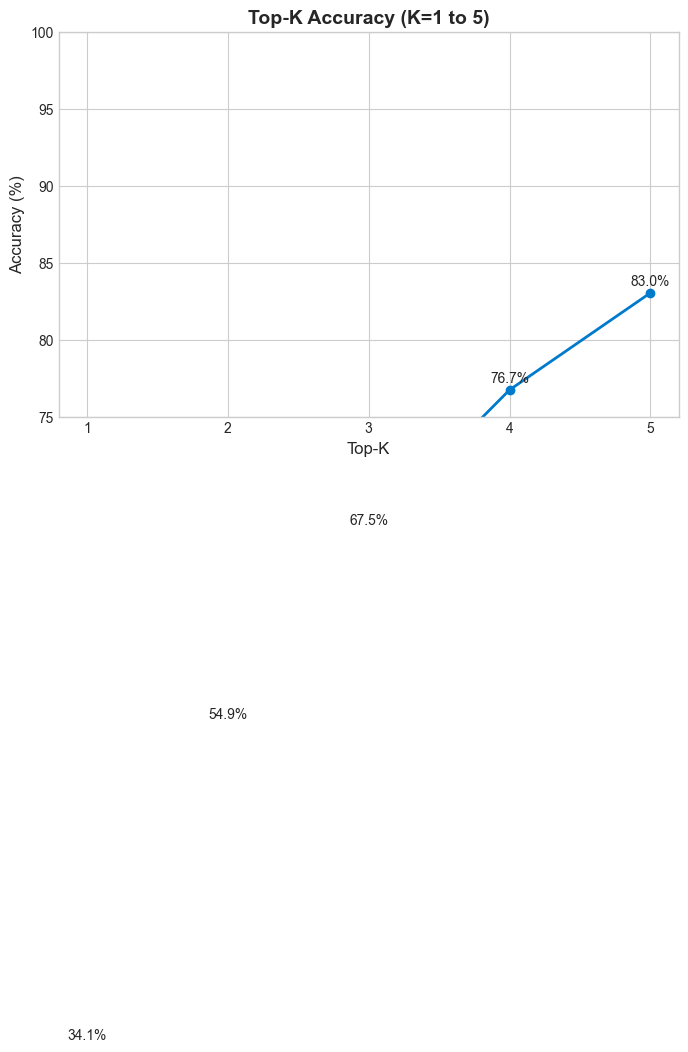

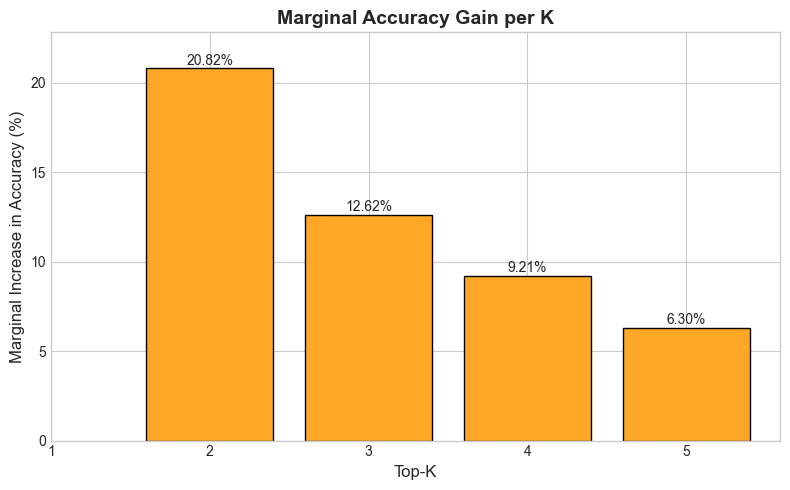

In [23]:
import matplotlib.pyplot as plt

# Compute top-K accuracies
topk_accuracies = [test_utils.topK_accuracy(true_lab, pred_lab, K=k) for k in range(1, 6)]
topk_accuracies = [acc * 100 for acc in topk_accuracies]  # Convert to percentages

# Set plot style
plt.style.use('seaborn-v0_8-whitegrid')

# Create figure
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(range(1, 6), topk_accuracies, marker='o', linestyle='-', color='#007acc', linewidth=2)

# Annotate each point
for k, acc in enumerate(topk_accuracies, start=1):
    ax.text(k, acc + 0.5, f"{acc:.1f}%", ha='center', fontsize=10)

# Customize axes and labels
ax.set_xticks(range(1, 6))
ax.set_xlabel('Top-K', fontsize=12)
ax.set_ylabel('Accuracy (%)', fontsize=12)
ax.set_title('Top-K Accuracy (K=1 to 5)', fontsize=14, fontweight='bold')
ax.set_ylim(75, 100)
ax.tick_params(axis='both', labelsize=10)

# Final layout and save
plt.tight_layout()
plt.show()


# Compute top-K accuracies (in %)
topk_accuracies = np.array([test_utils.topK_accuracy(true_lab, pred_lab, K=k) for k in range(1, 6)]) * 100

# Compute marginal increases
marginal_increase = np.diff(topk_accuracies, prepend=topk_accuracies[0])
marginal_increase[0] = np.nan  # No marginal increase for K=1

# Plot
plt.style.use('seaborn-v0_8-whitegrid')
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(range(1, 6), marginal_increase, color='#ffa726', edgecolor='black')

# Annotate bars
for bar, inc in zip(bars, marginal_increase):
    if not np.isnan(inc):
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, height + 0.2, f"{inc:.2f}%", ha='center', fontsize=10)

# Axis labels and formatting
ax.set_xticks(range(1, 6))
ax.set_xlabel('Top-K', fontsize=12)
ax.set_ylabel('Marginal Increase in Accuracy (%)', fontsize=12)
ax.set_title('Marginal Accuracy Gain per K', fontsize=14, fontweight='bold')
ax.set_ylim(0, max(marginal_increase[1:]) + 2)
ax.tick_params(axis='both', labelsize=10)

# Save and show
plt.tight_layout()
# plt.savefig("topk_marginal_increase.png", dpi=300)
plt.show()



## Computing the confusion matrix

### Standard confusion matrix

In [24]:
def plot_confusion_matrices(data, save_path=None, weighted=False,comments="normal"):
    """
    Plot confusion matrices and weighted confusion matrices for different thresholds using the provided data.

    Args:
        data (pandas.DataFrame): DataFrame containing the necessary data for plotting.
        save_path (str): Path where the plots will be saved.
        weighted (bool): Flag indicating whether to compute weighted confusion matrices.
    """

    # Define the labels
    class_names = np.unique(data["top1"])

    # Define the probability thresholds for the confusion-matrix figures
    thresholds = [0.00, 0.50]

    # Create the directory for saving the plots
    pred_path = create_pred_path(save_path, dir="confusion", weighted=weighted, comments=comments)


    # Iterate over the range
    for threshold in thresholds:
        # Get the current time
        current_time = datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S")
        label = int(round(threshold * 100))
        print(f"[{current_time}] Plotting Confusion Matrix for {label}")

        # Filter the data based on a condition
        slice = data[data["probability"] > threshold]

        # Extract true labels and predicted labels
        y_true = np.array(slice["true_label"])
        y_pred = np.array(slice["top1"])

        y_true = y_true.astype(str)
        y_pred = y_pred.astype(str)
        # Compute the confusion matrix
        weights = np.array(slice["probability"]) if weighted else None
        conf_mat = confusion_matrix(y_true, y_pred, labels=np.unique(y_pred), sample_weight=weights)

        # Normalize the confusion matrix
        normed_conf = conf_mat / np.sum(conf_mat, axis=1)[:, np.newaxis]

        # Plot the confusion matrix using the custom function plt_conf_matrix
        fig, ax = plt_conf_matrix(normed_conf, class_names)

        # Save the plot
        # Determine the file name suffix based on weighted option
        file_suffix = f"weighted_{label:02d}" if weighted else f"_{label:02d}"

        # Save the confusion matrix plot
        fig.savefig(f"{pred_path}/confusion_matrix{file_suffix}.jpg", bbox_inches='tight')
        plt.close(fig)
    rel_path = os.path.relpath(pred_path, start=Path.cwd())
    print(f"Saved in {rel_path}")


In [25]:
plot_confusion_matrices(data, save_path=False)


[2026-09-07 13:24:47] Plotting Confusion Matrix for 0
[2026-09-07 13:24:49] Plotting Confusion Matrix for 50
Saved in ..\models\2026-09-04_115513-eriozona\results\confusion\normal


### Weighted confusion matrix
We weight each count in the confusion matrix by the probability of the prediction.

In [26]:
# Create the directory for saving the plots
plot_confusion_matrices(data,save_path=False,weighted=True)


[2026-09-07 13:24:50] Plotting Confusion Matrix for 0
[2026-09-07 13:24:51] Plotting Confusion Matrix for 50
Saved in ..\models\2026-09-04_115513-eriozona\results\confusion\confusion_weighted


### Metrics evolution in function of cut-off 
The evolution of differnt metrics is shown for different cut-off values. All data below this cut-off is discarted when plotting new metrics.

In [27]:
def plot_evolution_cut_off(data, save_path=False,comments=""):
    """
    Plot the evolution of metrics with varying cutoff probability.

    Args:
        data (DataFrame): Input data containing "probability", "top1", and "true_label" columns.
        save_path (str): Path where the plots will be saved.

    Returns:
        None (plots are displayed and saved)
    """
    myrange = np.arange(0, 1, 0.02)

    pred_path = create_pred_path(save_path, dir="cut_off_changes",comments=comments)

    for cl in np.unique(data["top1"]):
        print(f"Plotting cutoff probability for {cl}")

        metrics = []
        data_slice = []

        for i in myrange:
            slice_data = data[data["probability"] > i]
            data_slice.append(compute_data_slice(slice_data, cl))

            TP, FP, FN, TN = calculate_confusion_matrix(slice_data, cl)
            precision, recall, outer_precision, outer_recall, f1_score, accuracy, specificity, fpr, fnr, auc_roc = compute_metrics(slice_data, cl, TP, FP, FN, TN)

            metrics.append((precision, recall, outer_precision, outer_recall, f1_score, accuracy, specificity, fpr, fnr, auc_roc))

        plot_metrics(myrange, metrics, data_slice, cl, pred_path)

    print("Plots saved in:", pred_path)




def compute_data_slice(slice_data, cl):
    return np.sum(slice_data['top1'] == cl) / np.sum(data['top1'] == cl)


def calculate_confusion_matrix(slice_data, cl):
    TP = np.sum((slice_data["true_label"] == cl) & (slice_data["top1"] == cl))
    FP = np.sum((slice_data["true_label"] != cl) & (slice_data["top1"] == cl))
    FN = np.sum((slice_data["true_label"] == cl) & (slice_data["top1"] != cl))
    TN = np.sum((slice_data["true_label"] != cl) & (slice_data["top1"] != cl))
    return TP, FP, FN, TN


def compute_metrics(slice_data, cl, TP, FP, FN, TN):
    precision = TP / (TP + FP)
    recall = TP / (TP + FN)
    outer_precision = TP / np.sum(slice_data["top1"] == cl)
    outer_recall = TP / np.sum(slice_data["true_label"] == cl)

    f1_score = 2 * (precision * recall) / (precision + recall)
    accuracy = (TP + TN) / (TP + TN + FP + FN)
    specificity = TN / (TN + FP)
    fpr = FP / (FP + TN)
    fnr = FN / (FN + TP)

    if np.sum((slice_data["true_label"] == cl)) != 0:
        auc_roc = roc_auc_score((slice_data["true_label"] == cl).astype(int), slice_data["probability"])
    else:
        auc_roc = 0

    return precision, recall, outer_precision, outer_recall, f1_score, accuracy, specificity, fpr, fnr, auc_roc


def plot_metrics(myrange, metrics, data_slice, cl, pred_path):
    plt.figure(figsize=(12, 8))
    cmap = plt.get_cmap('tab10')
    colors = cmap(np.linspace(0, 1, 12))

    plt.plot(myrange, [m[0] for m in metrics], label="Precision", linestyle='-', marker='o', color=colors[0])
    plt.plot(myrange, [m[1] for m in metrics], label="Recall", linestyle='--', marker='s', color=colors[1])
    plt.plot(myrange, data_slice, label="Loss of Predictions", linestyle='-', marker='*', color=colors[4])

    plt.plot(myrange, [m[2] for m in metrics], label="Outer Precision", linestyle=':', marker='^', color=colors[2])
    plt.plot(myrange, [m[3] for m in metrics], label="Outer Recall", linestyle='-.', marker='D', color=colors[3])

    plt.plot(myrange, [m[4] for m in metrics], label="F1 Score", linestyle='-', marker='x', color=colors[5])
    plt.plot(myrange, [m[5] for m in metrics], label="Accuracy", linestyle='--', marker='o', color=colors[6])
    plt.plot(myrange, [m[6] for m in metrics], label="Specificity", linestyle=':', marker='s', color=colors[7])
    plt.plot(myrange, [m[7] for m in metrics], label="False Positive Rate", linestyle='-.', marker='^', color=colors[8])
    plt.plot(myrange, [m[8] for m in metrics], label="False Negative Rate", linestyle='-', marker='D', color=colors[9])
    plt.plot(myrange, [m[9] for m in metrics], label="AUC-ROC", linestyle='--', marker='*', color=colors[10])

    plt.legend(loc='best', fontsize='medium')
    plt.xlabel("Cutoff value for probability", fontsize='large')
    plt.ylabel("Metric Score", fontsize='large')
    plt.title(cl, fontsize='x-large')

    plt.xticks(fontsize='medium')
    plt.yticks(fontsize='medium')

    plt.grid(True, linestyle='--', alpha=0.7)

    plt.savefig(f"{pred_path}/{cl.replace('/', '+')}.jpg", bbox_inches='tight')
    plt.close()


In [28]:
plot_evolution_cut_off(data, save_path=False)


Plotting cutoff probability for appendicularia_UMAP1_SOM1
Plotting cutoff probability for appendicularia_UMAP1_SOM2
Plotting cutoff probability for appendicularia_UMAP2_SOM1
Plotting cutoff probability for appendicularia_UMAP2_SOM3
Plotting cutoff probability for appendicularia_UMAP2_SOM4
Plotting cutoff probability for appendicularia_UMAP2_SOM8
Plotting cutoff probability for appendicularia_UMAP3_SOM1
Plotting cutoff probability for appendicularia_UMAP3_SOM4
Plotting cutoff probability for appendicularia_UMAP3_SOM5
Plotting cutoff probability for appendicularia_UMAP3_SOM6
Plotting cutoff probability for artefact_bubbles_UMAP1_SOM1
Plotting cutoff probability for artefact_bubbles_UMAP1_SOM2
Plotting cutoff probability for artefact_bubbles_UMAP1_SOM3
Plotting cutoff probability for artefact_bubbles_UMAP1_SOM4
Plotting cutoff probability for artefact_bubbles_UMAP1_SOM5
Plotting cutoff probability for artefact_bubbles_UMAP1_SOM6
Plotting cutoff probability for artefact_bubbles_UMAP1_SOM7


### The Proportional and absolute progression of TRUE class is shown


In [29]:
def plot_classwise_progression(data, save_path, comments=""):
    """
    Plot the class-wise progression of TRUE class distribution for different cutoff values.

    Args:
        data (pandas.DataFrame): DataFrame containing the necessary data for plotting.
    """

    # Define the range for iterations
    myrange = np.arange(0, 1, 0.02)

    # Create directory for saving results
    pred_path = create_pred_path(save_path, dir="proportional_progression", comments=comments)

    for cl in np.unique(data["top1"]):
        print(f"Plotting proportional progression for {cl}")
        compo = pd.DataFrame(data[data['top1'] == cl]["true_label"].value_counts())
        for j, i in enumerate(myrange):
            slice = data[data["probability"] > i]
            x = slice[slice['top1'] == cl]["true_label"].value_counts()
            compo[str(j)] = x

        compo = compo.drop("count", axis=1)
        plotdata = compo / compo.sum()
        plotdata1 = plotdata[plotdata > 0.01] * 100
        plotdata2 = compo[plotdata > 0.01]
        plotdata1.columns = myrange
        plotdata2.columns = myrange

        fig, axs = plt.subplots(1, 2, figsize=(16, 6), sharex=True)

        # Plot left subplot
        ax1 = axs[0]
        handles1, labels1 = plotdata1.dropna(how="all").transpose().plot.area(
            ax=ax1,
            xlabel="Cutoff value for probability",
            legend=False,
            title="Proportional progression of TRUE class distribution",
        ).get_legend_handles_labels()
        ax1.set_ylabel("Class proportion (%)", fontsize=14)
        ax1.set_xlabel("Cutoff value for probability", fontsize=14)
        ax1.tick_params(labelsize=14)
        ax1.title.set_size(14)

        # Plot right subplot
        ax2 = axs[1]
        plotdata2.dropna(how="all").transpose().plot.area(
            ax=ax2,
            xlabel="Cutoff value for probability",
            legend=False,
            title="Absolute progression of TRUE class distribution"
        )
        ax2.set_ylabel("Class count", fontsize=14)
        ax2.set_xlabel("Cutoff value for probability", fontsize=14)
        ax2.tick_params(labelsize=14)
        ax2.title.set_size(14)

        # Shared legend below both plots
        fig.legend(handles1, labels1, loc='lower center', ncol=5, fontsize=12, bbox_to_anchor=(0.5, 0.02))

        # Overall title
        # plt.suptitle(cl, fontsize=14)

        # Adjust layout to make space for everything
        plt.tight_layout(rect=[0, 0.15, 1, 0.90])  # more room for legend and title

        # Show (or save if desired)
        plt.savefig(f"{pred_path}/{cl.replace('/', '+')}.jpg", bbox_inches='tight')
        plt.close()


In [30]:
plot_classwise_progression(data,save_path=False)


Plotting proportional progression for appendicularia_UMAP1_SOM1
Plotting proportional progression for appendicularia_UMAP1_SOM2
Plotting proportional progression for appendicularia_UMAP2_SOM1
Plotting proportional progression for appendicularia_UMAP2_SOM3
Plotting proportional progression for appendicularia_UMAP2_SOM4
Plotting proportional progression for appendicularia_UMAP2_SOM8
Plotting proportional progression for appendicularia_UMAP3_SOM1
Plotting proportional progression for appendicularia_UMAP3_SOM4
Plotting proportional progression for appendicularia_UMAP3_SOM5
Plotting proportional progression for appendicularia_UMAP3_SOM6
Plotting proportional progression for artefact_bubbles_UMAP1_SOM1
Plotting proportional progression for artefact_bubbles_UMAP1_SOM2
Plotting proportional progression for artefact_bubbles_UMAP1_SOM3
Plotting proportional progression for artefact_bubbles_UMAP1_SOM4
Plotting proportional progression for artefact_bubbles_UMAP1_SOM5
Plotting proportional progress

**Define cutoff - Nic**

In [31]:
# Function to define the cutoff probability for a given class
def define_cutoff(data, cl, p_aim=0.95):
    # Slice the data for the specific class and sort it in descending order based on probability
    slice = data[data["top1"] == cl].sort_values(by="probability", ascending=False).reset_index()
    # Calculate the precision for each position in the slice
    prec_list = np.cumsum(slice["top1_correct"]) / (slice.index + 1)
    # Find the positions where precision exceeds the desired aim
    acceptable_probabs = np.where(prec_list > p_aim)[0]
    if len(acceptable_probabs) > 0:
        # Return the minimum probability from the acceptable positions
        return np.min(slice['probability'][acceptable_probabs])
    else:
        # If no acceptable positions, return infinity
        return np.inf

# Function to apply the mask to the data based on the cutoff probabilities
def apply_mask(data, mask_data):
    # Initialize a mask with False values for each data point
    data_mask = np.repeat(False, len(data))
    for _, x in mask_data.iterrows():
        # Update the mask where the class and probability satisfy the cutoff criteria
        data_mask[(data["top1"] == x["Class"]) & (data["probability"] >= x["probability_cutoff"])] = True
    # Return the masked data
    return data[data_mask]

def mask_creater(p_aim,data):
    mask = [[x, define_cutoff(data, x, p_aim=p_aim)] for x in np.unique(data['top1'])]
    mask_data = pd.DataFrame(mask, columns=['Class', "probability_cutoff"])
    masked_data = apply_mask(data, mask_data)
    return masked_data 


In [32]:
def plot_summary_threshold(data, save_path=False,comments=""):
    """
    Plot the scores on a masked DataFrame with aimed precision.

    Args:
        data (pandas.DataFrame): DataFrame containing the necessary data for plotting.
        name (str): Name of the plot.
    """

    # Define the range of precision values to aim for
    myrange = np.concatenate((np.arange(0.5, 0.95, 0.01), np.arange(0.95, 0.995, 0.005)))

    # Create directory for saving results
    pred_path = create_pred_path(save_path, dir="summary_threshold",comments=comments)

    # Initialize arrays to store the evaluation metrics
    acc= np.zeros(len(myrange))
    pr_weighted = np.zeros(len(myrange))
    rec_weighted = np.zeros(len(myrange))
    f1_weighted = np.zeros(len(myrange))
    pr_macro = np.zeros(len(myrange))
    rec_macro = np.zeros(len(myrange))
    f1_macro = np.zeros(len(myrange))
    dataset_prop = np.zeros(len(myrange))
    class_prop = np.zeros(len(myrange))

    # Calculate evaluation metrics for each precision value
    for i, p_aim in enumerate(tqdm(myrange, desc='Processing')):
        masked_data =mask_creater(p_aim,data)

        dataset_prop[i] = len(masked_data) / len(data)
        class_prop[i] = len(np.unique(masked_data["top1"])) / len(np.unique(data["top1"]))
        acc[i] = accuracy_score(y_true=masked_data["true_label"], y_pred=masked_data["top1"])#, average="weighted")
        pr_weighted[i] = precision_score(y_true=masked_data["true_label"], y_pred=masked_data["top1"], average="weighted")
        rec_weighted[i] = recall_score(y_true=masked_data["true_label"], y_pred=masked_data["top1"], average="weighted")
        f1_weighted[i] = f1_score(y_true=masked_data["true_label"], y_pred=masked_data["top1"], average="weighted")
        # pr_macro[i] = precision_score(y_true=masked_data["true_label"], y_pred=masked_data["top1"], average="macro", zero_division=1)
        # rec_macro[i] = recall_score(y_true=masked_data["true_label"], y_pred=masked_data["top1"], average="macro", zero_division=1)
        # f1_macro[i] = f1_score(y_true=masked_data["true_label"], y_pred=masked_data["top1"], average="macro", zero_division=1)
        # acc[i] = accuracy_score(y_true=masked_data["true_label"], y_pred=masked_data["top1"])
        # pr_micro[i] = precision_score(y_true=masked_data["true_label"], y_pred=masked_data["top1"], average="micro",)
        # rec_micro[i] = recall_score(y_true=masked_data["true_label"], y_pred=masked_data["top1"], average="micro")
        # f1_micro[i] = f1_score(y_true=masked_data["true_label"], y_pred=masked_data["top1"], average="micro")
        # pr_macro[i] = precision_score(y_true=masked_data["true_label"], y_pred=masked_data["top1"], average="macro", zero_division=1)
        # rec_macro[i] = recall_score(y_true=masked_data["true_label"], y_pred=masked_data["top1"], average="macro", zero_division=1)
        # f1_macro[i] = f1_score(y_true=masked_data["true_label"], y_pred=masked_data["top1"], average="macro", zero_division=1)

    print("done!")

    # Create a DataFrame to show the evaluation metrics for different precision values
    show_data = pd.DataFrame({
        "Accuracy": acc,
        "Precision (weighted)": pr_weighted,
        "Recall (weighted)": rec_weighted,
        "F1 Score (weighted)": f1_weighted,
        "Dataset Proportion": dataset_prop,
        "Class Proportion": class_prop
    }, index=myrange)

    # Plot the evaluation metrics
    plt.figure(figsize=(12, 8))
    
    # Define custom colors for each metric line
    colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b"]#, "#e377c2", "#7f7f7f", "#bcbd22", "#17becf"]

    # Plot each metric with a different color and line style
    for i, metric in enumerate(show_data.columns):
        if metric in ["Dataset Proportion", "Class Proportion"]:
            plt.plot(show_data.index, show_data[metric], marker='o', linestyle='--', color=colors[i], label=metric, alpha=0.7)
        elif metric=="Accuracy":
            # print(show_data[metric])
            plt.plot(show_data.index, show_data[metric], marker='x', color=colors[i], label=metric, alpha=1,markersize=10)
        else:
            plt.plot(show_data.index, show_data[metric], marker='o', color=colors[i], label=metric, alpha=0.7)

    plt.title("Scores on after masking increasing thresholds")
    plt.xlabel("Probability Threshold ")
    plt.xticks(rotation=45)
    # plt.yticks(np.arange(0, 1.1, 0.1))
    plt.legend()
    plt.tight_layout()

    # Save the plot
    filename = os.path.join(pred_path, "summary_threshold_plot.jpg")
    plt.savefig(filename)
    rel_path = os.path.relpath(filename, start=Path.cwd())
    print(f"Saved in {rel_path}")
    plt.show()


done!
Saved in ..\models\2026-09-04_115513-eriozona\results\summary_threshold\saved_0.5\summary_threshold_plot.jpg


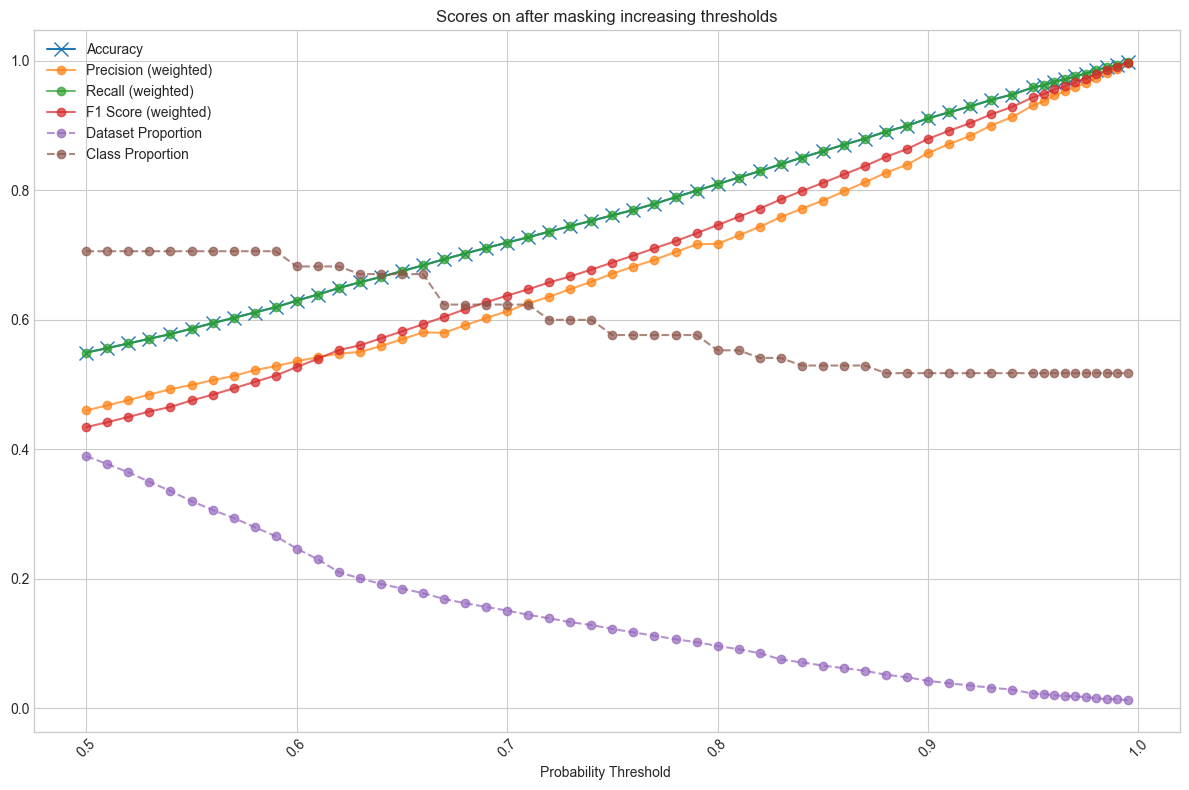

In [33]:
plot_summary_threshold(data,comments="saved_0.5")
